In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "8"
# pip install scikit-learn xgboost lightgbm imbalanced-learn joblib
import sys
from pathlib import Path
import pandas as pd

sys.path.append(str(Path("..").resolve()))
from src.utils import load_freq, load_sev
from src.modelado import (
    preparar_datos, dividir_datos, armar_xy, ejecutar_experimentos,
    leer_checkpoints, mejores_por_tarea, cargar_modelo, evaluar_prima_pura,
)

df_freq = load_freq("freMTPL2freq.csv")
df_sev  = load_sev("freMTPL2sev.csv")

df = preparar_datos(df_freq, df_sev)
df_train, df_test = dividir_datos(df)          # split por póliza, estratificado por ClaimNb>0

print(f"Train: {len(df_train):,} | Test: {len(df_test):,}")
print(f"% con siniestro  train: {(df_train.ClaimNb>0).mean():.4f} | test: {(df_test.ClaimNb>0).mean():.4f}")

Train: 542,405 | Test: 135,602
% con siniestro  train: 0.0368 | test: 0.0368


In [2]:
MODO_PRUEBA = False      # True: corrida corta para validar; False: corrida completa

if MODO_PRUEBA:
    CARPETA, N_ITER, CV_FOLDS = "models_prueba", 3, 3
    df_tr = df_train.sample(frac=0.05, random_state=42)   # ~27k pólizas
else:
    CARPETA, N_ITER, CV_FOLDS = "models", 15, 5
    df_tr = df_train

N_JOBS, USAR_GPU, SAMPLING_RATIO = -1, False, 0.2   # ratio minoría/mayoría tras SMOTE/ADASYN

MODELOS    = ["GLM", "XGBoost", "LightGBM"]
BALANCEOS  = ["sin_balanceo", "weights", "smote", "adasyn"]

In [5]:
X_tr_f, y_tr_f = armar_xy(df_tr,   "freq")
X_te_f, y_te_f = armar_xy(df_test, "freq")

ck = ejecutar_experimentos(
    "freq", MODELOS, BALANCEOS, X_tr_f, y_tr_f, X_te_f, y_te_f,
    carpeta=CARPETA, n_iter=N_ITER, cv_folds=CV_FOLDS,
    n_jobs=1, threads_modelo=8,          # 8 núcleos físicos
    usar_gpu=USAR_GPU, sampling_ratio=SAMPLING_RATIO,
)

[1/12] freq|GLM|sin_balanceo  -> ya existe en checkpoints, se omite
[2/12] freq|GLM|weights ...
      CV dev=0.25398 | test dev=0.25325 | MAE=0.09521 | RMSE=0.20593 | Gini=0.271 | sesgo=1.649 | 132.4s
[3/12] freq|GLM|smote ...


c:\Users\User\miniconda3\envs\brent-dl\lib\site-packages\threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


      CV dev=0.37973 | test dev=0.37827 | MAE=0.18219 | RMSE=0.25995 | Gini=0.259 | sesgo=4.174 | 211.2s
[4/12] freq|GLM|adasyn ...
      CV dev=0.39558 | test dev=0.39376 | MAE=0.19121 | RMSE=0.26730 | Gini=0.257 | sesgo=4.430 | 635.0s
[5/12] freq|XGBoost|sin_balanceo ...
      CV dev=0.23619 | test dev=0.23589 | MAE=0.07178 | RMSE=0.20109 | Gini=0.316 | sesgo=0.998 | 303.2s
[6/12] freq|XGBoost|weights ...
      CV dev=0.24271 | test dev=0.24255 | MAE=0.08710 | RMSE=0.20293 | Gini=0.311 | sesgo=1.449 | 292.6s
[7/12] freq|XGBoost|smote ...
      CV dev=0.24943 | test dev=0.24976 | MAE=0.09297 | RMSE=0.20456 | Gini=0.284 | sesgo=1.582 | 510.9s
[8/12] freq|XGBoost|adasyn ...
      CV dev=0.24826 | test dev=0.24809 | MAE=0.09117 | RMSE=0.20413 | Gini=0.289 | sesgo=1.530 | 904.0s
[9/12] freq|LightGBM|sin_balanceo ...
      CV dev=0.23600 | test dev=0.23568 | MAE=0.07184 | RMSE=0.20104 | Gini=0.317 | sesgo=0.998 | 170.2s
[10/12] freq|LightGBM|weights ...
      CV dev=0.24348 | test dev=0.24

In [6]:
X_tr_s, y_tr_s = armar_xy(df_tr,   "sev")
X_te_s, y_te_s = armar_xy(df_test, "sev")

ck = ejecutar_experimentos(
    "sev", MODELOS, ["sin_balanceo"], X_tr_s, y_tr_s, X_te_s, y_te_s,
    carpeta=CARPETA, n_iter=N_ITER, cv_folds=CV_FOLDS,
    n_jobs=N_JOBS, usar_gpu=USAR_GPU,
)

[1/3] sev|GLM|sin_balanceo ...
      CV dev=1.68435 | test dev=1.60403 | MAE=2037.44857 | RMSE=9014.67249 | Gini=0.024 | sesgo=1.032 | 7.4s
[2/3] sev|XGBoost|sin_balanceo ...
      CV dev=1.62261 | test dev=1.54581 | MAE=1883.71547 | RMSE=9002.47457 | Gini=0.109 | sesgo=0.939 | 6.4s
[3/3] sev|LightGBM|sin_balanceo ...
      CV dev=1.66299 | test dev=1.58260 | MAE=1847.53470 | RMSE=9008.62259 | Gini=0.065 | sesgo=0.913 | 4.2s


In [7]:
ck = leer_checkpoints(CARPETA)
cols = ["task","modelo","balanceo","cv_deviance","test_deviance","test_mae","test_rmse",
        "test_gini","test_bias","train_deviance","tiempo_busqueda_s","status"]
display(ck[cols].sort_values(["task","cv_deviance"]).round(5))

display(mejores_por_tarea(ck)[["task","modelo","balanceo","cv_deviance","test_deviance","best_params"]])

,task,modelo,balanceo,cv_deviance,test_deviance,test_mae,test_rmse,test_gini,test_bias,train_deviance,tiempo_busqueda_s,status
8,freq,LightGBM,sin_balanceo,0.23600,0.23568,0.07184,0.20104,0.31708,0.99825,0.23112,170.2,ok
4,freq,XGBoost,sin_balanceo,0.23619,0.23589,0.07178,0.20109,0.31566,0.99844,0.23089,303.2,ok
11,freq,LightGBM,adasyn,0.23976,0.23948,0.07969,0.20227,0.29995,1.22044,0.22879,679.4,ok
10,freq,LightGBM,smote,0.24002,0.23969,0.08012,0.20228,0.29799,1.23214,0.22925,294.8,ok
0,freq,GLM,sin_balanceo,0.24230,0.24168,0.07293,0.20270,0.27056,0.99734,0.24210,88.6,ok
5,freq,XGBoost,weights,0.24271,0.24255,0.08710,0.20293,0.31054,1.44924,0.24047,292.6,ok
9,freq,LightGBM,weights,0.24348,0.24323,0.08797,0.20349,0.31278,1.48534,0.22956,177.6,ok
7,freq,XGBoost,adasyn,0.24826,0.24809,0.09117,0.20413,0.28942,1.52999,0.24619,904.0,ok
6,freq,XGBoost,smote,0.24943,0.24976,0.09297,0.20456,0.28393,1.58217,0.24795,510.9,ok
1,freq,GLM,weights,0.25398,0.25325,0.09521,0.20593,0.27085,1.64880,0.25377,132.4,ok


,task,modelo,balanceo,cv_deviance,test_deviance,best_params
0,freq,LightGBM,sin_balanceo,0.235998,0.235682,"{""estimator__colsample_bytree"": 0.916597455868..."
1,sev,XGBoost,sin_balanceo,1.622605,1.545807,"{""estimator__colsample_bytree"": 0.544246251025..."


In [8]:
mej = mejores_por_tarea(ck).set_index("task")
m_f = cargar_modelo("freq", mej.loc["freq","modelo"], mej.loc["freq","balanceo"], CARPETA)
m_s = cargar_modelo("sev",  mej.loc["sev","modelo"],  mej.loc["sev","balanceo"],  CARPETA)
print(evaluar_prima_pura(m_f, m_s, df_test))

{'mae': 147.42479546558675, 'rmse': 2030.8767650882844, 'tweedie_dev': 65.53359399517993, 'gini': 0.2791744270755343, 'bias': 0.9455859974644072}


In [3]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "8"

import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone

sys.path.append(str(Path("..").resolve()))
from src.utils import load_freq, load_sev
from src.modelado import (
    preparar_datos, dividir_datos, armar_xy, crear_cv, leer_checkpoints,
    mejores_por_tarea, cargar_modelo, calcular_metricas, TASKS,
)

CARPETA, CV_FOLDS = "models", 5          # corrida completa
TAREAS = ["freq", "sev"]

df = preparar_datos(load_freq("freMTPL2freq.csv"), load_sev("freMTPL2sev.csv"))
df_train, df_test = dividir_datos(df)
print(f"Train: {len(df_train):,} | Test: {len(df_test):,}")     # esperado: 542,405 | 135,602

DATOS = {}
for t in TAREAS:
    X_tr, y_tr = armar_xy(df_train, t)
    X_te, y_te = armar_xy(df_test, t)
    DATOS[t] = dict(X_tr=X_tr, y_tr=y_tr, X_te=X_te, y_te=y_te,
                    wcol=TASKS[t]["weight_col"])

# IDpol de cada fila del test (para ordenar residuos en el ACF)
IDS_TE = {"freq": df_test["IDpol"].to_numpy(),
          "sev":  df_test.loc[df_test["ClaimNb"] > 0, "IDpol"].to_numpy()}

# modelos guardados + predicciones en test
ck_ok = leer_checkpoints(CARPETA)
ck_ok = ck_ok[ck_ok["status"] == "ok"].drop_duplicates(["task", "modelo", "balanceo"], keep="last")

MODELOS, PRED_TE = {}, {t: {} for t in TAREAS}
for r in ck_ok.itertuples():
    nombre = f"{r.modelo}|{r.balanceo}"
    m = cargar_modelo(r.task, r.modelo, r.balanceo, CARPETA)
    MODELOS[(r.task, nombre)] = m
    PRED_TE[r.task][nombre] = m.predict(DATOS[r.task]["X_te"])

MEJOR = {r.task: f"{r.modelo}|{r.balanceo}" for r in mejores_por_tarea(ck_ok).itertuples()}
print("Mejor por tarea:", MEJOR)

# verificación: la deviance recalculada debe coincidir con la del CSV
for t in TAREAS:
    D = DATOS[t]
    m = calcular_metricas(t, D["y_te"], PRED_TE[t][MEJOR[t]], D["X_te"][D["wcol"]])
    fila = ck_ok[(ck_ok.task == t) & (ck_ok.modelo + "|" + ck_ok.balanceo == MEJOR[t])].iloc[0]
    print(f"{t}: test dev recalculada = {m['deviance']:.5f} | CSV = {fila.test_deviance:.5f}")

Train: 542,405 | Test: 135,602
Mejor por tarea: {'freq': 'LightGBM|sin_balanceo', 'sev': 'XGBoost|sin_balanceo'}
freq: test dev recalculada = 0.23568 | CSV = 0.23568
sev: test dev recalculada = 1.54581 | CSV = 1.54581


In [2]:
# pip install statsmodels
from scipy.special import xlogy
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.graphics.tsaplots import plot_acf
import statsmodels.api as sm


def residuos(task, y, pred, w, tipo="cuantil", seed=42):
    """freq: y=ClaimNb, pred=tasa, w=Exposure | sev: y=sev. media, pred=sev. media, w=ClaimNb."""
    y, pred, w = (np.asarray(a, float) for a in (y, pred, w))
    if task == "freq":
        mu = pred * w
        if tipo == "pearson":
            return (y - mu) / np.sqrt(mu)
        if tipo == "deviance":
            d = 2 * (xlogy(y, y / mu) - (y - mu))
            return np.sign(y - mu) * np.sqrt(np.maximum(d, 0))
        rng = np.random.default_rng(seed)                       # cuantil aleatorizado (Poisson)
        u = rng.uniform(stats.poisson.cdf(y - 1, mu), stats.poisson.cdf(y, mu))
    else:
        mu = pred
        if tipo == "pearson":
            return np.sqrt(w) * (y - mu) / mu
        if tipo == "deviance":
            d = 2 * w * (-np.log(y / mu) + (y - mu) / mu)
            return np.sign(y - mu) * np.sqrt(np.maximum(d, 0))
        phi = np.sum(w * ((y - mu) / mu) ** 2) / len(y)         # dispersión Gamma estimada
        u = stats.gamma.cdf(y, a=w / phi, scale=mu * phi / w)
    return stats.norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))


def diagnostico_residuos(task, nombre, tipo="cuantil", lags=20, n_bins=10, seed=42):
    D = DATOS[task]
    y = D["y_te"].to_numpy(float)
    w = D["X_te"][D["wcol"]].to_numpy(float)
    pred = PRED_TE[task][nombre]
    res = residuos(task, y, pred, w, tipo, seed)
    ajust = pred * w if task == "freq" else pred          # media ajustada de cada observación

    o_id = np.argsort(IDS_TE[task], kind="mergesort")
    o_fit = np.argsort(ajust, kind="mergesort")
    rng = np.random.default_rng(seed)

    # ── pruebas ──────────────────────────────────────────────
    bp = het_breuschpagan(res, sm.add_constant(np.log(ajust)))
    rho, p_rho = stats.spearmanr(np.abs(res), ajust)
    lb_id = acorr_ljungbox(res[o_id], lags=[10, lags], return_df=True)
    lb_fit = acorr_ljungbox(res[o_fit], lags=[10, lags], return_df=True)
    jb = stats.jarque_bera(res)
    da = stats.normaltest(res)
    sh = stats.shapiro(rng.choice(res, size=min(5000, len(res)), replace=False))
    ks = stats.kstest(res, "norm")

    filas = [
        ("Media del residuo", res.mean(), np.nan),
        ("Desviación estándar", res.std(), np.nan),
        ("Asimetría", stats.skew(res), np.nan),
        ("Curtosis (exceso)", stats.kurtosis(res), np.nan),
        ("Breusch-Pagan (residuo ~ log ajustado)", bp[0], bp[1]),
        ("Spearman |residuo| vs ajustado (rho)", rho, p_rho),
    ]
    for k in sorted({10, lags}):
        filas.append((f"Ljung-Box lag {k} · orden IDpol", lb_id.loc[k, "lb_stat"], lb_id.loc[k, "lb_pvalue"]))
    for k in sorted({10, lags}):
        filas.append((f"Ljung-Box lag {k} · orden por ajustado", lb_fit.loc[k, "lb_stat"], lb_fit.loc[k, "lb_pvalue"]))
    filas += [
        ("Jarque-Bera", jb[0], jb[1]),
        ("D'Agostino-Pearson", da[0], da[1]),
        ("Shapiro-Wilk (muestra ≤5,000)", sh[0], sh[1]),
        ("Kolmogorov-Smirnov vs N(0,1)", ks[0], ks[1]),
    ]
    tabla = pd.DataFrame(filas, columns=["prueba", "estadístico", "p-valor"])

    # ── gráficos ─────────────────────────────────────────────
    fig, ax = plt.subplots(2, 3, figsize=(17, 9))
    grupo = pd.qcut(pd.Series(ajust).rank(method="first"), n_bins, labels=False).to_numpy()
    gb = pd.DataFrame({"g": grupo, "r": res, "a": ajust}).groupby("g")

    # 1) residuos vs ajustados
    s = rng.choice(len(res), size=min(15000, len(res)), replace=False)
    ax[0, 0].scatter(ajust[s], res[s], s=4, alpha=0.25)
    ax[0, 0].plot(gb["a"].median(), gb["r"].mean(), "r-o", label="media por grupo")
    ax[0, 0].plot(gb["a"].median(), gb["r"].std(), "k--s", label="desv. est. por grupo")
    ax[0, 0].axhline(0, color="gray", lw=.8)
    ax[0, 0].set_xscale("log"); ax[0, 0].set_xlabel("Valor ajustado"); ax[0, 0].set_ylabel("Residuo")
    ax[0, 0].set_title("Residuos vs ajustados"); ax[0, 0].legend()

    # 2) homocedasticidad: dispersión por grupo
    ax[0, 1].bar(range(1, n_bins + 1), gb["r"].std())
    ax[0, 1].axhline(res.std(), color="r", ls="--", label="desv. global")
    ax[0, 1].set_xlabel("Grupo de valor ajustado"); ax[0, 1].set_ylabel("Desv. est. del residuo")
    ax[0, 1].set_title(f"Homocedasticidad (Breusch-Pagan p = {bp[1]:.3g})"); ax[0, 1].legend()

    # 3) histograma + normal
    ax[0, 2].hist(res, bins=80, range=(-5, 5), density=True, alpha=.7)
    xx = np.linspace(-5, 5, 400)
    ax[0, 2].plot(xx, stats.norm.pdf(xx, res.mean(), res.std()), "r-", label="Normal ajustada")
    ax[0, 2].set_title("Histograma de residuos (eje recortado a ±5)"); ax[0, 2].legend()

    # 4) QQ-plot
    q = np.sort(rng.choice(res, size=min(20000, len(res)), replace=False))
    teo = stats.norm.ppf((np.arange(1, len(q) + 1) - .5) / len(q))
    ax[1, 0].plot(teo, q, ".", ms=3)
    ax[1, 0].plot([-4, 4], [-4, 4], "r-")
    ax[1, 0].set_xlabel("Cuantiles teóricos N(0,1)"); ax[1, 0].set_ylabel("Cuantiles muestrales")
    ax[1, 0].set_title("QQ-plot")

    # 5-6) ACF + Ljung-Box
    plot_acf(res[o_id], lags=lags, zero=False, ax=ax[1, 1],
             title=f"ACF · orden IDpol | Ljung-Box p(lag {lags}) = {lb_id.loc[lags, 'lb_pvalue']:.3g}")
    plot_acf(res[o_fit], lags=lags, zero=False, ax=ax[1, 2],
             title=f"ACF · orden por ajustado | Ljung-Box p(lag {lags}) = {lb_fit.loc[lags, 'lb_pvalue']:.3g}")

    fig.suptitle(f"Diagnóstico de residuos ({tipo}) · {task} · {nombre} · test", fontsize=14)
    plt.tight_layout(); plt.show()
    return tabla


for t in TAREAS:
    display(diagnostico_residuos(t, MEJOR[t]).round(4))

: 

,task,modelo,balanceo,cv_deviance,test_deviance,test_mae,test_rmse,test_gini,test_bias,train_deviance,tiempo_busqueda_s,status
8,freq,LightGBM,sin_balanceo,0.23600,0.23568,0.07184,0.20104,0.31708,0.99825,0.23112,170.2,ok
4,freq,XGBoost,sin_balanceo,0.23619,0.23589,0.07178,0.20109,0.31566,0.99844,0.23089,303.2,ok
11,freq,LightGBM,adasyn,0.23976,0.23948,0.07969,0.20227,0.29995,1.22044,0.22879,679.4,ok
10,freq,LightGBM,smote,0.24002,0.23969,0.08012,0.20228,0.29799,1.23214,0.22925,294.8,ok
0,freq,GLM,sin_balanceo,0.24230,0.24168,0.07293,0.20270,0.27056,0.99734,0.24210,88.6,ok
5,freq,XGBoost,weights,0.24271,0.24255,0.08710,0.20293,0.31054,1.44924,0.24047,292.6,ok
9,freq,LightGBM,weights,0.24348,0.24323,0.08797,0.20349,0.31278,1.48534,0.22956,177.6,ok
7,freq,XGBoost,adasyn,0.24826,0.24809,0.09117,0.20413,0.28942,1.52999,0.24619,904.0,ok
6,freq,XGBoost,smote,0.24943,0.24976,0.09297,0.20456,0.28393,1.58217,0.24795,510.9,ok
1,freq,GLM,weights,0.25398,0.25325,0.09521,0.20593,0.27085,1.64880,0.25377,132.4,ok


,task,modelo,balanceo,cv_deviance,test_deviance,best_params
0,freq,LightGBM,sin_balanceo,0.235998,0.235682,"{""estimator__colsample_bytree"": 0.916597455868..."
1,sev,XGBoost,sin_balanceo,1.622605,1.545807,"{""estimator__colsample_bytree"": 0.544246251025..."



freq · LightGBM|sin_balanceo
   fold 1/5 listo
   fold 2/5 listo
   fold 3/5 listo
   fold 4/5 listo
   fold 5/5 listo


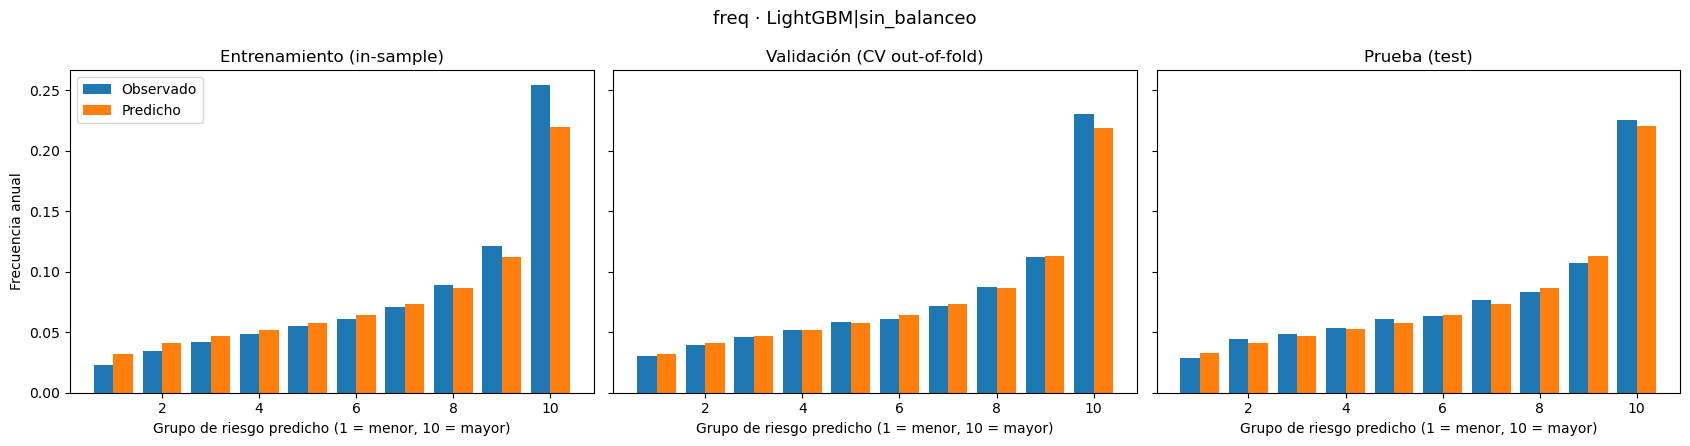

,deviance,mae,rmse,gini,bias
subconjunto,,,,,
Entrenamiento (in-sample),0.23112,0.07154,0.19980,0.38637,0.99859
Validación (CV out-of-fold),0.23600,0.07189,0.20084,0.33268,0.99809
Prueba (test),0.23568,0.07184,0.20104,0.31708,0.99825



sev · XGBoost|sin_balanceo
   fold 1/5 listo
   fold 2/5 listo
   fold 3/5 listo
   fold 4/5 listo
   fold 5/5 listo


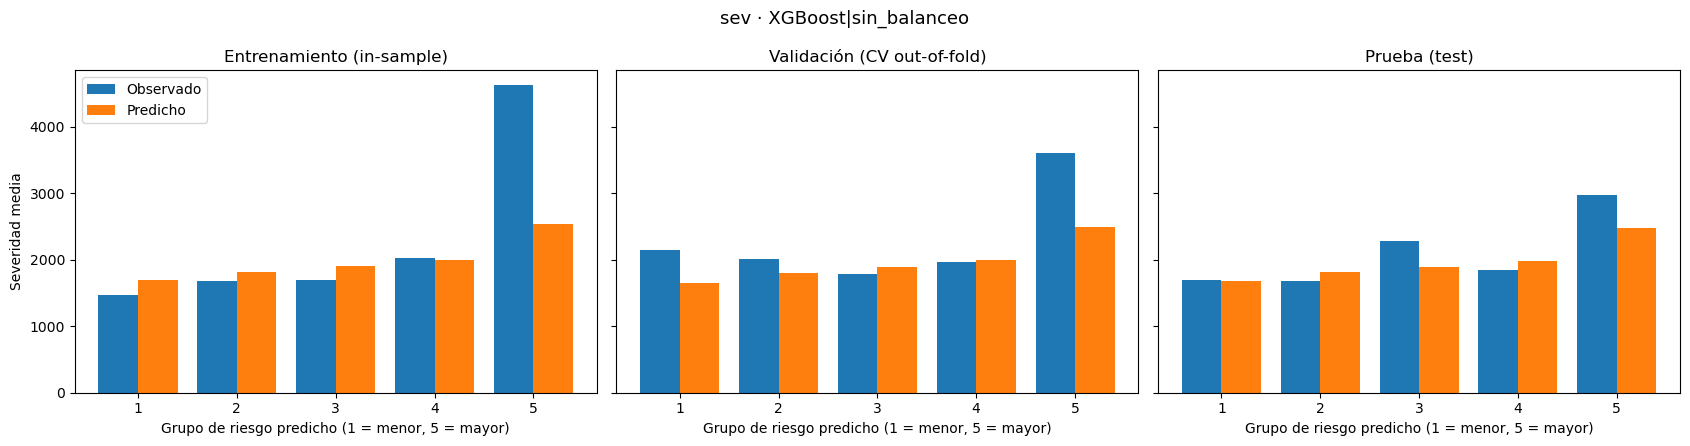

,deviance,mae,rmse,gini,bias
subconjunto,,,,,
Entrenamiento (in-sample),1.41732,2085.57776,31422.07526,0.26750,0.86220
Validación (CV out-of-fold),1.62256,2079.77671,31624.75940,0.11896,0.85203
Prueba (test),1.54581,1883.71547,9002.47457,0.10889,0.93861


In [4]:
# ── 2.1 Tabla que ya tenías ──────────────────────────────────
ck = leer_checkpoints(CARPETA)
cols = ["task","modelo","balanceo","cv_deviance","test_deviance","test_mae","test_rmse",
        "test_gini","test_bias","train_deviance","tiempo_busqueda_s","status"]
display(ck[cols].sort_values(["task", "cv_deviance"]).round(5))
display(mejores_por_tarea(ck)[["task","modelo","balanceo","cv_deviance","test_deviance","best_params"]])


# ── 2.2 Gráfico train / validación (OOF) / test ──────────────
def predicciones_subconjuntos(task, nombre):
    D = DATOS[task]; X_tr, y_tr = D["X_tr"], D["y_tr"]
    base = MODELOS[(task, nombre)]
    pred_tr = base.predict(X_tr)
    pred_va = np.full(len(y_tr), np.nan)
    for i, (itr, iva) in enumerate(crear_cv(X_tr, y_tr, task, CV_FOLDS), 1):
        m = clone(base).fit(X_tr.iloc[itr], y_tr.iloc[itr])     # mismos hiperparámetros del mejor
        pred_va[iva] = m.predict(X_tr.iloc[iva])
        print(f"   fold {i}/{CV_FOLDS} listo")
    return pred_tr, pred_va, PRED_TE[task][nombre]


def curva_calibracion(task, y, pred, w, n_bins):
    obs, est = (y, pred * w) if task == "freq" else (y * w, pred * w)
    b = pd.qcut(pd.Series(pred).rank(method="first"), n_bins, labels=False).to_numpy()
    g = pd.DataFrame({"b": b, "obs": obs, "est": est, "w": w}).groupby("b").sum()
    return (g["obs"] / g["w"]).to_numpy(), (g["est"] / g["w"]).to_numpy()


def grafico_subconjuntos(task, nombre, n_bins=None):
    n_bins = n_bins or (10 if task == "freq" else 5)
    D = DATOS[task]
    y_tr = D["y_tr"].to_numpy(float); w_tr = D["X_tr"][D["wcol"]].to_numpy(float)
    y_te = D["y_te"].to_numpy(float); w_te = D["X_te"][D["wcol"]].to_numpy(float)
    p_tr, p_va, p_te = predicciones_subconjuntos(task, nombre)

    sets = {"Entrenamiento (in-sample)": (y_tr, p_tr, w_tr),
            "Validación (CV out-of-fold)": (y_tr, p_va, w_tr),
            "Prueba (test)": (y_te, p_te, w_te)}
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
    filas = []
    for ax, (tit, (y, p, w)) in zip(axs, sets.items()):
        o, e = curva_calibracion(task, y, p, w, n_bins)
        x = np.arange(1, len(o) + 1)
        ax.bar(x - 0.2, o, 0.4, label="Observado")
        ax.bar(x + 0.2, e, 0.4, label="Predicho")
        ax.set_title(tit)
        ax.set_xlabel(f"Grupo de riesgo predicho (1 = menor, {n_bins} = mayor)")
        filas.append({"subconjunto": tit, **calcular_metricas(task, y, p, w)})
    axs[0].set_ylabel("Frecuencia anual" if task == "freq" else "Severidad media")
    axs[0].legend()
    fig.suptitle(f"{task} · {nombre}", fontsize=13)
    plt.tight_layout(); plt.show()
    return pd.DataFrame(filas).set_index("subconjunto").round(5)


for t in TAREAS:
    print(f"\n{t} · {MEJOR[t]}")
    display(grafico_subconjuntos(t, MEJOR[t]))

In [5]:
from scipy.special import xlogy
from scipy.stats import rankdata, norm
from sklearn.metrics import roc_curve
from statsmodels.stats.multitest import multipletests


# ══════════════ Diebold-Mariano ══════════════
def perdida_individual(task, y, pred, w, tipo="deviance"):
    y, pred, w = (np.asarray(a, float) for a in (y, pred, w))
    if task == "freq":
        mu = pred * w
        return 2 * (xlogy(y, y / mu) - (y - mu)) if tipo == "deviance" else (y - mu) ** 2
    esc = len(w) / w.sum()                    # así la media coincide con la métrica ponderada
    if tipo == "deviance":
        return w * 2 * (-np.log(y / pred) + (y - pred) / pred) * esc
    return w * (y - pred) ** 2 * esc


def dm_test(l1, l2, h=1):
    """H0: misma precisión. dif>0 => el modelo 1 pierde más (el 2 es mejor)."""
    d = np.asarray(l1) - np.asarray(l2)
    n, dbar = len(d), d.mean()
    lrv = np.var(d)
    for k in range(1, h):                     # Newey-West (solo si h>1)
        lrv += 2 * (1 - k / h) * np.mean((d[k:] - dbar) * (d[:-k] - dbar))
    if lrv <= 0:
        return dict(dm=np.nan, p=np.nan, dif=dbar)
    z = dbar / np.sqrt(lrv / n)
    return dict(dm=z, p=2 * norm.sf(abs(z)), dif=dbar)


def tabla_dm(task, ref=None, perdida="deviance"):
    ref = ref or MEJOR[task]
    D = DATOS[task]
    y = D["y_te"].to_numpy(float); w = D["X_te"][D["wcol"]].to_numpy(float)
    L = {n: perdida_individual(task, y, p, w, perdida) for n, p in PRED_TE[task].items()}
    filas = []
    for n in L:
        if n == ref:
            continue
        r = dm_test(L[n], L[ref])
        filas.append(dict(modelo=n, perdida_media=L[n].mean(), dif_vs_ref=r["dif"], DM=r["dm"], p=r["p"]))
    t = pd.DataFrame(filas)
    t["p_holm"] = multipletests(t["p"].fillna(1), method="holm")[1]
    t["veredicto"] = np.where(
        t["p_holm"] < 0.05,
        np.where(t["dif_vs_ref"] > 0, "referencia significativamente mejor", "este modelo es significativamente mejor"),
        "sin diferencia significativa")
    print(f"[{task}] referencia = {ref} | pérdida media ref = {L[ref].mean():.5f} | pérdida: {perdida}")
    return t.sort_values("perdida_media").reset_index(drop=True)


def dm_matriz(task, perdida="deviance"):
    """p-valores DM por pares (fila vs columna), sin ajustar por comparaciones múltiples."""
    D = DATOS[task]
    y = D["y_te"].to_numpy(float); w = D["X_te"][D["wcol"]].to_numpy(float)
    L = {n: perdida_individual(task, y, p, w, perdida) for n, p in PRED_TE[task].items()}
    P = pd.DataFrame(np.nan, index=list(L), columns=list(L))
    for a in L:
        for b in L:
            if a != b:
                P.loc[a, b] = dm_test(L[a], L[b])["p"]
    return P


# ══════════════ DeLong (solo frecuencia, ClaimNb>0) ══════════════
def delong_test(y_bin, s1, s2):
    y_bin = np.asarray(y_bin).astype(int)
    orden = np.argsort(-y_bin, kind="mergesort")           # positivos primero
    m = int(y_bin.sum()); n = len(y_bin) - m
    S = np.vstack([s1, s2])[:, orden]
    pos, neg = S[:, :m], S[:, m:]
    tz = np.array([rankdata(s) for s in S])
    tx = np.array([rankdata(s) for s in pos])
    ty = np.array([rankdata(s) for s in neg])
    auc = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (auc[0] - auc[1]) / np.sqrt(var) if var > 0 else np.nan
    return dict(auc1=auc[0], auc2=auc[1], z=z, p=2 * norm.sf(abs(z)))


def tabla_delong(ref=None, graficar=True):
    ref = ref or MEJOR["freq"]
    D = DATOS["freq"]
    y_bin = (D["y_te"].to_numpy() > 0).astype(int)
    w = D["X_te"]["Exposure"].to_numpy(float)
    S = {n: p * w for n, p in PRED_TE["freq"].items()}      # siniestros esperados
    filas = []
    for n in S:
        if n == ref:
            continue
        r = delong_test(y_bin, S[n], S[ref])
        filas.append(dict(modelo=n, AUC=r["auc1"], dif_AUC_vs_ref=r["auc1"] - r["auc2"], z=r["z"], p=r["p"]))
    t = pd.DataFrame(filas)
    t["p_holm"] = multipletests(t["p"].fillna(1), method="holm")[1]
    t["veredicto"] = np.where(
        t["p_holm"] < 0.05,
        np.where(t["dif_AUC_vs_ref"] < 0, "referencia significativamente mejor", "este modelo es significativamente mejor"),
        "sin diferencia significativa")
    auc_ref = delong_test(y_bin, S[ref], S[ref])["auc1"]
    print(f"[freq] referencia = {ref} | AUC ref = {auc_ref:.4f}")

    if graficar:
        top = sorted(S, key=lambda n: -delong_test(y_bin, S[n], S[ref])["auc1"])[:5]
        plt.figure(figsize=(6, 5))
        for n in top:
            fpr, tpr, _ = roc_curve(y_bin, S[n])
            plt.plot(fpr, tpr, label=f"{n} (AUC={delong_test(y_bin, S[n], S[ref])['auc1']:.3f})")
        plt.plot([0, 1], [0, 1], "k--", lw=.8)
        plt.xlabel("1 - Especificidad"); plt.ylabel("Sensibilidad")
        plt.title("ROC: ¿hay al menos un siniestro? (top 5 por AUC)"); plt.legend(fontsize=8)
        plt.tight_layout(); plt.show()
    return t.sort_values("AUC", ascending=False).reset_index(drop=True)


# ══════════════ Bootstrap ══════════════
def bootstrap_metricas(task, nombres, ref=None, n_boot=500, seed=42, alpha=0.05):
    """Remuestrea pólizas del test con reemplazo (mismo remuestreo para todos los modelos => diferencias pareadas)."""
    ref = ref or MEJOR[task]
    nombres = list(dict.fromkeys([ref] + list(nombres)))
    D = DATOS[task]
    y = D["y_te"].to_numpy(float); w = D["X_te"][D["wcol"]].to_numpy(float); n = len(y)
    claves = ["deviance", "mae", "rmse", "gini", "bias"]
    rng = np.random.default_rng(seed)
    B = {nm: {k: np.empty(n_boot) for k in claves} for nm in nombres}
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        for nm in nombres:
            m = calcular_metricas(task, y[idx], PRED_TE[task][nm][idx], w[idx])
            for k in claves:
                B[nm][k][b] = m[k]
        if (b + 1) % 50 == 0:
            print(f"   [{task}] bootstrap {b + 1}/{n_boot}", flush=True)

    q = [100 * alpha / 2, 100 * (1 - alpha / 2)]
    filas = []
    for nm in nombres:
        punto = calcular_metricas(task, y, PRED_TE[task][nm], w)
        for k in claves:
            lo, hi = np.percentile(B[nm][k], q)
            filas.append(dict(modelo=nm, metrica=k, estimado=punto[k],
                              ee_boot=B[nm][k].std(ddof=1), ic_inf=lo, ic_sup=hi))
    res = pd.DataFrame(filas)

    dif = []
    for nm in nombres:
        if nm == ref:
            continue
        for k in ["deviance", "gini"]:
            d = B[nm][k] - B[ref][k]
            lo, hi = np.percentile(d, q)
            dif.append(dict(modelo=nm, metrica=k, dif_media=d.mean(), ic_inf=lo, ic_sup=hi,
                            ic_excluye_cero=bool(lo > 0 or hi < 0)))
    return res, pd.DataFrame(dif)


def grafico_bootstrap(res, task):
    fig, axs = plt.subplots(1, 2, figsize=(14, 0.6 * res["modelo"].nunique() + 2.5))
    for ax, k in zip(axs, ["deviance", "gini"]):
        r = res[res.metrica == k].sort_values("estimado").reset_index(drop=True)
        xerr = [np.clip(r.estimado - r.ic_inf, 0, None), np.clip(r.ic_sup - r.estimado, 0, None)]
        ax.errorbar(r.estimado, range(len(r)), xerr=xerr, fmt="o", capsize=3)
        ax.set_yticks(range(len(r))); ax.set_yticklabels(r.modelo)
        ax.set_title(f"{k} en test (IC 95% bootstrap)")
    fig.suptitle(f"Estabilidad de las métricas · {task}")
    plt.tight_layout(); plt.show()

[freq] referencia = LightGBM|sin_balanceo | pérdida media ref = 0.23568 | pérdida: deviance


,modelo,perdida_media,dif_vs_ref,DM,p,p_holm,veredicto
0,XGBoost|sin_balanceo,0.23589,0.00020,1.52792,0.12653,0.12653,sin diferencia significativa
1,LightGBM|adasyn,0.23948,0.00380,11.46876,0.00000,0.00000,referencia significativamente mejor
2,LightGBM|smote,0.23969,0.00401,11.81515,0.00000,0.00000,referencia significativamente mejor
3,GLM|sin_balanceo,0.24168,0.00599,14.05619,0.00000,0.00000,referencia significativamente mejor
4,XGBoost|weights,0.24255,0.00687,16.32830,0.00000,0.00000,referencia significativamente mejor
5,LightGBM|weights,0.24323,0.00755,16.51938,0.00000,0.00000,referencia significativamente mejor
6,XGBoost|adasyn,0.24809,0.01241,22.37635,0.00000,0.00000,referencia significativamente mejor
7,XGBoost|smote,0.24976,0.01408,24.07516,0.00000,0.00000,referencia significativamente mejor
8,GLM|weights,0.25325,0.01756,27.29757,0.00000,0.00000,referencia significativamente mejor
9,GLM|smote,0.37827,0.14259,88.89821,0.00000,0.00000,referencia significativamente mejor


[freq] referencia = LightGBM|sin_balanceo | pérdida media ref = 0.04042 | pérdida: mse


,modelo,perdida_media,dif_vs_ref,DM,p,p_holm,veredicto
0,XGBoost|sin_balanceo,0.04044,0.00002,1.08983,0.27579,0.27579,sin diferencia significativa
1,LightGBM|adasyn,0.04091,0.00050,13.78633,0.00000,0.00000,referencia significativamente mejor
2,LightGBM|smote,0.04092,0.00050,14.04268,0.00000,0.00000,referencia significativamente mejor
3,GLM|sin_balanceo,0.04109,0.00067,11.09898,0.00000,0.00000,referencia significativamente mejor
4,XGBoost|weights,0.04118,0.00076,17.21172,0.00000,0.00000,referencia significativamente mejor
5,LightGBM|weights,0.04141,0.00099,16.36367,0.00000,0.00000,referencia significativamente mejor
6,XGBoost|adasyn,0.04167,0.00125,25.68714,0.00000,0.00000,referencia significativamente mejor
7,XGBoost|smote,0.04184,0.00143,27.82801,0.00000,0.00000,referencia significativamente mejor
8,GLM|weights,0.04241,0.00199,29.50093,0.00000,0.00000,referencia significativamente mejor
9,GLM|smote,0.06757,0.02716,100.62314,0.00000,0.00000,referencia significativamente mejor


[sev] referencia = XGBoost|sin_balanceo | pérdida media ref = 1.54581 | pérdida: deviance


,modelo,perdida_media,dif_vs_ref,DM,p,p_holm,veredicto
0,LightGBM|sin_balanceo,1.58260,0.03679,1.79234,0.07308,0.07308,sin diferencia significativa
1,GLM|sin_balanceo,1.60403,0.05822,2.62625,0.00863,0.01727,referencia significativamente mejor


[sev] referencia = XGBoost|sin_balanceo | pérdida media ref = 81044548.34478 | pérdida: mse


,modelo,perdida_media,dif_vs_ref,DM,p,p_holm,veredicto
0,LightGBM|sin_balanceo,8.115528e+07,110732.59798,1.21146,0.22572,0.2926,sin diferencia significativa
1,GLM|sin_balanceo,8.126432e+07,219771.74539,1.45273,0.14630,0.2926,sin diferencia significativa


[freq] referencia = LightGBM|sin_balanceo | AUC ref = 0.7089


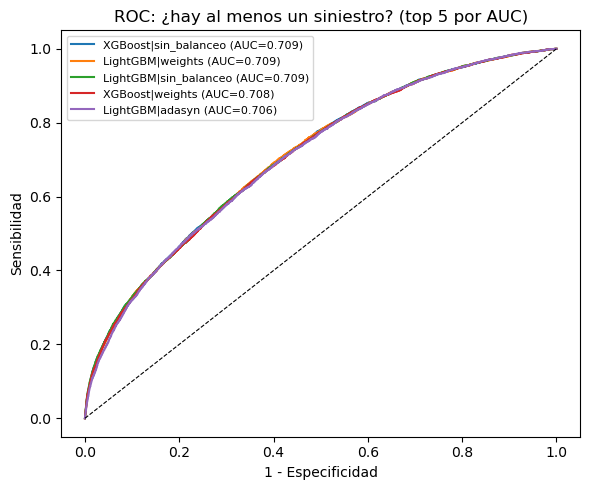

,modelo,AUC,dif_AUC_vs_ref,z,p,p_holm,veredicto
0,XGBoost|sin_balanceo,0.70939,0.00047,0.99359,0.32042,0.64085,sin diferencia significativa
1,LightGBM|weights,0.70909,0.00017,0.28035,0.77921,0.77921,sin diferencia significativa
2,XGBoost|weights,0.70765,-0.00127,-2.75523,0.00587,0.02346,referencia significativamente mejor
3,LightGBM|adasyn,0.70624,-0.00268,-2.66420,0.00772,0.02346,referencia significativamente mejor
4,LightGBM|smote,0.70505,-0.00387,-3.89679,0.00010,0.00049,referencia significativamente mejor
5,XGBoost|adasyn,0.69870,-0.01021,-8.63117,0.00000,0.00000,referencia significativamente mejor
6,XGBoost|smote,0.69775,-0.01116,-9.21043,0.00000,0.00000,referencia significativamente mejor
7,GLM|sin_balanceo,0.69406,-0.01485,-10.96504,0.00000,0.00000,referencia significativamente mejor
8,GLM|weights,0.69386,-0.01506,-11.11225,0.00000,0.00000,referencia significativamente mejor
9,GLM|smote,0.68982,-0.01909,-12.46014,0.00000,0.00000,referencia significativamente mejor


   [freq] bootstrap 50/500
   [freq] bootstrap 100/500
   [freq] bootstrap 150/500
   [freq] bootstrap 200/500
   [freq] bootstrap 250/500
   [freq] bootstrap 300/500
   [freq] bootstrap 350/500
   [freq] bootstrap 400/500
   [freq] bootstrap 450/500
   [freq] bootstrap 500/500


,modelo,metrica,estimado,ee_boot,ic_inf,ic_sup
0,LightGBM|sin_balanceo,deviance,0.23568,0.00267,0.23011,0.24077
1,LightGBM|sin_balanceo,mae,0.07184,0.00051,0.07072,0.07279
2,LightGBM|sin_balanceo,rmse,0.20104,0.00169,0.19764,0.20405
3,LightGBM|sin_balanceo,gini,0.31708,0.00788,0.30163,0.33196
4,LightGBM|sin_balanceo,bias,0.99825,0.01422,0.97173,1.02746
5,XGBoost|sin_balanceo,deviance,0.23589,0.00269,0.23023,0.24106
6,XGBoost|sin_balanceo,mae,0.07178,0.00051,0.07066,0.07273
7,XGBoost|sin_balanceo,rmse,0.20109,0.00169,0.19767,0.20407
8,XGBoost|sin_balanceo,gini,0.31566,0.00805,0.30015,0.33108
9,XGBoost|sin_balanceo,bias,0.99844,0.01422,0.97224,1.02755


,modelo,metrica,dif_media,ic_inf,ic_sup,ic_excluye_cero
0,XGBoost|sin_balanceo,deviance,0.00020,-0.00005,0.00044,False
1,XGBoost|sin_balanceo,gini,-0.00143,-0.00462,0.00164,False
2,LightGBM|adasyn,deviance,0.00380,0.00318,0.00444,True
3,LightGBM|adasyn,gini,-0.01695,-0.02320,-0.01043,True
4,LightGBM|smote,deviance,0.00403,0.00338,0.00475,True
5,LightGBM|smote,gini,-0.01908,-0.02499,-0.01288,True
6,GLM|sin_balanceo,deviance,0.00598,0.00512,0.00672,True
7,GLM|sin_balanceo,gini,-0.04647,-0.05420,-0.03772,True


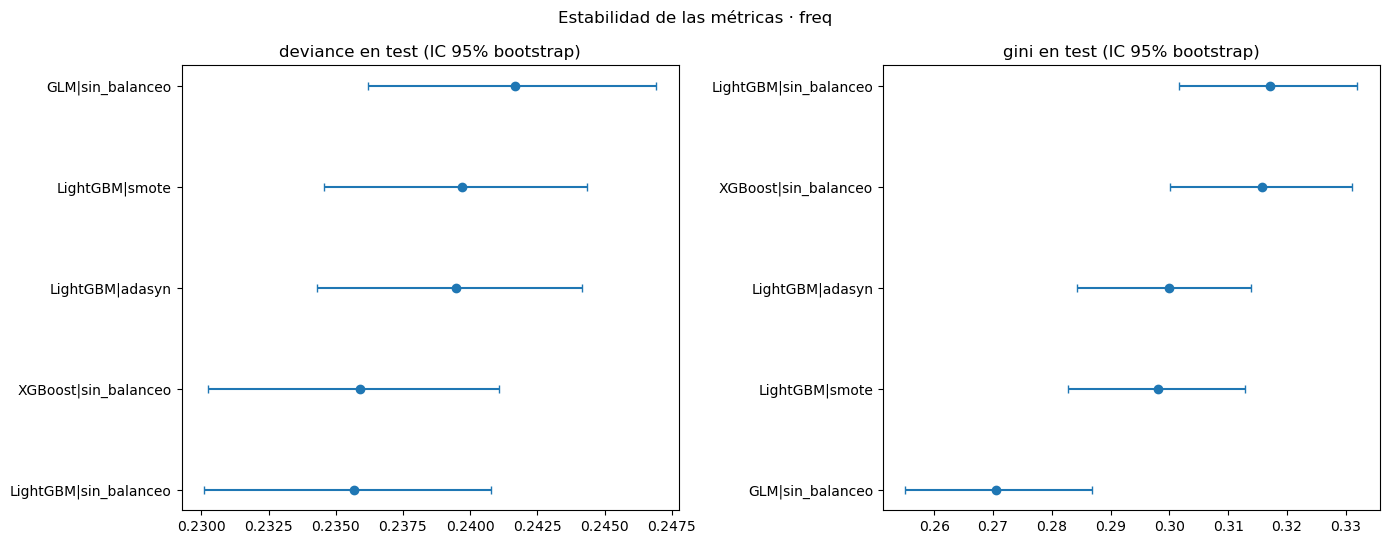

   [sev] bootstrap 50/1000
   [sev] bootstrap 100/1000
   [sev] bootstrap 150/1000
   [sev] bootstrap 200/1000
   [sev] bootstrap 250/1000
   [sev] bootstrap 300/1000
   [sev] bootstrap 350/1000
   [sev] bootstrap 400/1000
   [sev] bootstrap 450/1000
   [sev] bootstrap 500/1000
   [sev] bootstrap 550/1000
   [sev] bootstrap 600/1000
   [sev] bootstrap 650/1000
   [sev] bootstrap 700/1000
   [sev] bootstrap 750/1000
   [sev] bootstrap 800/1000
   [sev] bootstrap 850/1000
   [sev] bootstrap 900/1000
   [sev] bootstrap 950/1000
   [sev] bootstrap 1000/1000


,modelo,metrica,estimado,ee_boot,ic_inf,ic_sup
0,XGBoost|sin_balanceo,deviance,1.54581,0.12262,1.31984,1.80389
1,XGBoost|sin_balanceo,mae,1883.71547,132.93579,1647.02759,2156.44490
2,XGBoost|sin_balanceo,rmse,9002.47457,1382.03662,6213.91666,11603.60903
3,XGBoost|sin_balanceo,gini,0.10889,0.03817,0.03587,0.18034
4,XGBoost|sin_balanceo,bias,0.93861,0.06053,0.82691,1.06300
5,LightGBM|sin_balanceo,deviance,1.58260,0.13942,1.33120,1.88489
6,LightGBM|sin_balanceo,mae,1847.53470,132.96150,1610.72161,2124.31943
7,LightGBM|sin_balanceo,rmse,9008.62259,1384.25946,6216.65406,11612.97006
8,LightGBM|sin_balanceo,gini,0.06535,0.04328,-0.01749,0.14628
9,LightGBM|sin_balanceo,bias,0.91311,0.05897,0.80395,1.03196


,modelo,metrica,dif_media,ic_inf,ic_sup,ic_excluye_cero
0,LightGBM|sin_balanceo,deviance,0.03626,0.00226,0.07854,True
1,LightGBM|sin_balanceo,gini,-0.04170,-0.09079,-0.00085,True
2,GLM|sin_balanceo,deviance,0.05761,0.01371,0.10227,True
3,GLM|sin_balanceo,gini,-0.08284,-0.15137,-0.02345,True


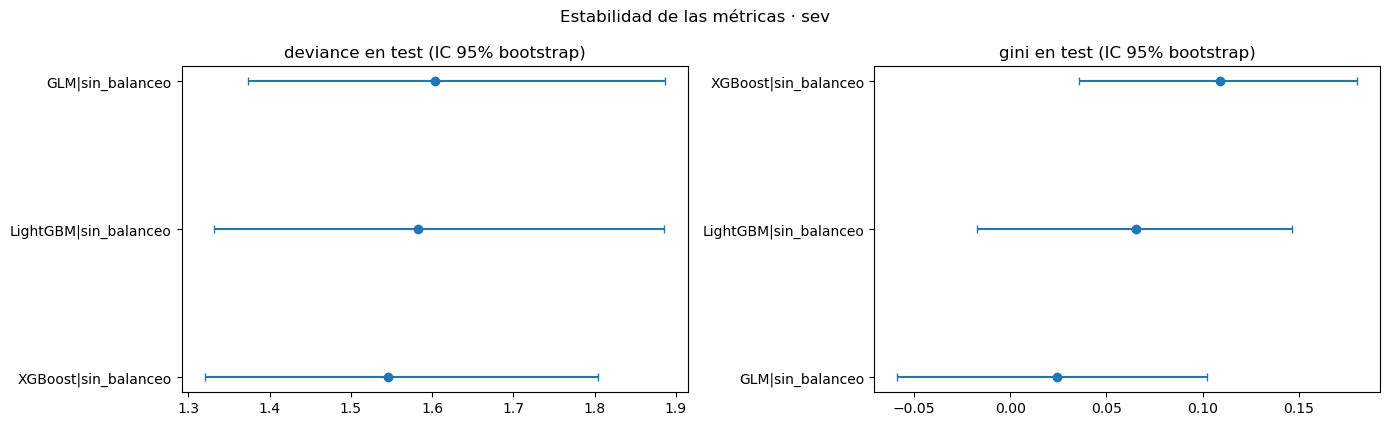

In [6]:
# ── Diebold-Mariano ──
for t in TAREAS:
    display(tabla_dm(t).round(5))                          # pérdida = deviance (criterio principal)
    display(tabla_dm(t, perdida="mse").round(5))           # robustez con error cuadrático
# matriz por pares (opcional):
# display(dm_matriz("freq").round(4).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=0.1))

# ── DeLong (frecuencia) ──
display(tabla_delong().round(5))

# ── Bootstrap: top 5 por CV deviance en cada tarea ──
top = {t: (lambda d: (d.modelo + "|" + d.balanceo).tolist())(ck_ok[ck_ok.task == t].nsmallest(5, "cv_deviance"))
       for t in TAREAS}

res_f, dif_f = bootstrap_metricas("freq", top["freq"], n_boot=500)   # prueba antes con n_boot=100
display(res_f.round(5)); display(dif_f.round(5)); grafico_bootstrap(res_f, "freq")

res_s, dif_s = bootstrap_metricas("sev", top["sev"], n_boot=1000)    # solo ~5 mil pólizas: rápido
display(res_s.round(5)); display(dif_s.round(5)); grafico_bootstrap(res_s, "sev")